# 1. Setup and Imports

In [2]:
# 1) Imports
import pandas as pd
import numpy as np

#Viaulization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing for machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#MSE, R2, Accuracy, F1 Score.
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, 
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
)

print("Libraries are imported.")



Libraries are imported.


# 2. Data Loading and Initial Exploration of the Data

In [13]:
file_path = 'medical_insurance.csv' 
df = pd.read_csv(file_path)

pd.options.display.max_columns = None
pd.options.display.max_rows = None

print("Dataset contains {} rows and {} columns.".format(df.shape[0], df.shape[1]))
print("-" * 45)

print("Data is loaded. The 10 rows of the dataset:")
display(df.head(10))

Dataset contains 100000 rows and 54 columns.
---------------------------------------------
Data is loaded. The 10 rows of the dataset:


,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,bmi,smoker,alcohol_freq,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,diastolic_bp,ldl,hba1c,plan_type,network_tier,deductible,copay,policy_term_years,policy_changes_last_2yrs,provider_quality,risk_score,annual_medical_cost,annual_premium,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,hypertension,diabetes,asthma,copd,cardiovascular_disease,cancer_history,kidney_disease,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,1,27.4,Never,NaN,2,0,0,4,121.0,76.0,123.8,5.28,PPO,Bronze,1000,20,4,0,3.73,0.5714,6938.06,876.05,73.00,1,4672.59,4672.59,1,0,0,0,0,0,0,0,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,1,26.6,Never,Weekly,2,0,0,3,131.0,79.0,97.3,4.82,POS,Gold,1000,10,1,0,3.10,1.0000,1632.61,445.10,37.09,4,297.27,1189.08,2,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,3,31.5,Never,NaN,1,0,0,4,160.0,84.0,129.5,5.51,HMO,Platinum,500,20,10,0,3.90,1.0000,7661.01,1538.02,128.17,0,0.00,0.00,3,1,0,0,0,0,1,0,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,3,31.6,Never,NaN,0,0,0,1,104.0,68.0,160.3,8.50,HMO,Silver,500,20,5,0,3.89,0.2857,5130.27,820.63,68.39,0,0.00,0.00,1,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,0,30.5,Never,Daily,3,0,0,2,136.0,83.0,171.0,5.20,POS,Platinum,500,10,7,0,3.90,0.8681,1700.73,500.93,41.74,1,1002.24,1002.24,2,1,0,0,0,0,0,0,0,1,0,2,0,1,1,0,1,0
5,76435,63,Female,North,Rural,305000.0,HS,Single,Employed,3,2,20.4,Never,Daily,1,0,0,2,137.0,96.0,69.2,5.70,HMO,Silver,500,20,5,0,4.66,0.6923,2697.34,528.68,44.06,1,1220.04,1220.04,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0
6,84005,36,Male,West,Rural,38900.0,Masters,Single,Employed,1,0,21.6,Never,Occasional,0,0,0,0,114.0,76.0,153.9,5.54,HMO,Silver,500,10,3,0,4.30,0.1978,1746.68,414.60,34.55,0,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0
7,80918,21,Female,South,Suburban,83700.0,HS,Single,Employed,3,2,30.7,Never,Weekly,3,0,0,1,82.0,64.0,189.0,7.01,HMO,Gold,2000,20,6,0,4.65,0.3187,1564.03,445.22,37.10,2,703.03,1406.06,1,0,1,0,0,0,0,0,0,0,0,2,1,0,0,1,0,1
8,60768,53,Male,North,Suburban,60700.0,No HS,Divorced,Retired,1,0,27.8,Current,NaN,0,0,0,0,138.0,84.0,151.5,5.52,HMO,Gold,1000,10,4,0,4.38,0.8571,5684.12,1028.51,85.71,0,0.00,0.00,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0
9,50075,28,Male,South,Urban,23600.0,Bachelors,Married,Employed,4,2,31.0,Never,Weekly,0,0,0,0,99.0,62.0,108.6,4.49,EPO,Gold,500,10,4,0,3.24,0.1978,4150.00,802.60,66.88,0,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0


DATASET INFORMATION

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 54 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   sex                          100000 non-null  object 
 3   region                       100000 non-null  object 
 4   urban_rural                  100000 non-null  object 
 5   income                       100000 non-null  float64
 6   education                    100000 non-null  object 
 7   marital_status               100000 non-null  object 
 8   employment_status            100000 non-null  object 
 9   household_size               100000 non-null  int64  
 10  dependents                   100000 non-null  int64  
 11  bmi                          100000 non-null  float64
 12  smoker                       100000 no

,Missing Count,Percentage (%)
alcohol_freq,30083,30.083


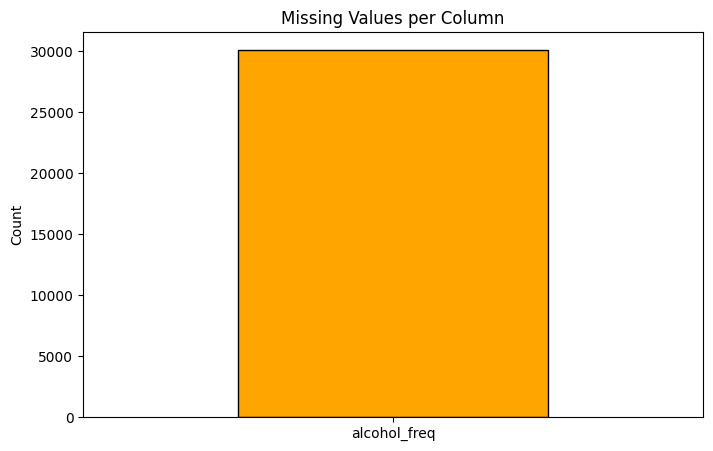

In [43]:
print("DATASET INFORMATION\n")
df.info()
print(60 * "-")

print("MISSING VALUE ANALYSIS")
print("-" * 30)

# Count the missing values
missing_count = df.isnull().sum()
missing_count = missing_count[missing_count > 0]

if not missing_count.empty:
    # 1. Şık bir tablo olarak gösterelim
    missing_df = pd.DataFrame({
        'Missing Count': missing_count,
        'Percentage (%)': (missing_count / len(df)) * 100
    })
    display(missing_df)

    # Draw a graphic
    plt.figure(figsize=(8, 5))
    missing_count.plot(kind='bar', color='orange', edgecolor='black')
    plt.title('Missing Values per Column', fontsize=12)
    plt.ylabel('Count')
    plt.xticks(rotation=0) 
    plt.show()
else:
    print("No missing values found in the dataset.")

In [28]:
print("Statistical Information:")
df.describe()

Statistical Information:


,person_id,age,income,household_size,dependents,bmi,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,diastolic_bp,ldl,hba1c,deductible,copay,policy_term_years,policy_changes_last_2yrs,provider_quality,risk_score,annual_medical_cost,annual_premium,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,hypertension,diabetes,asthma,copd,cardiovascular_disease,cancer_history,kidney_disease,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
count,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,50000.500000,47.521500,4.987390e+04,2.430900,0.898380,26.990512,1.92765,0.093640,0.373350,1.236320,117.808970,73.604770,119.975065,5.605968,1226.725000,19.520400,5.517760,0.050690,3.598920,0.519849,3009.451907,582.320040,48.526668,1.62178,656.512084,1377.878827,0.724720,0.203450,0.085930,0.058870,0.035950,0.051170,0.021510,0.014620,0.014770,0.108310,0.130140,0.508530,0.158690,0.508390,0.50933,0.509140,0.367810,0.169700
std,28867.657797,15.988752,4.680021e+04,1.075126,0.950654,4.994883,1.73773,0.304848,1.373011,1.209358,15.369187,8.900924,30.262086,0.845996,1019.619375,10.286255,2.868827,0.224591,0.594052,0.250669,3127.462822,399.583722,33.298640,2.02982,1072.660048,2305.464687,0.805523,0.402566,0.280262,0.235382,0.186166,0.220345,0.145078,0.120027,0.120632,0.310773,0.336459,0.749755,0.463562,0.747218,0.75363,0.750455,0.482212,0.375371
min,1.000000,0.000000,1.100000e+03,1.000000,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000,61.000000,40.000000,30.000000,3.540000,500.000000,10.000000,1.000000,0.000000,1.500000,0.000000,55.550000,211.670000,17.640000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,25000.750000,37.000000,2.110000e+04,2.000000,0.000000,23.600000,1.00000,0.000000,0.000000,0.000000,107.000000,67.000000,99.400000,5.160000,500.000000,10.000000,3.000000,0.000000,3.200000,0.329700,1175.117500,352.070000,29.340000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,50000.500000,48.000000,3.620000e+04,2.000000,1.000000,27.000000,2.00000,0.000000,0.000000,1.000000,117.000000,73.000000,120.000000,5.440000,1000.000000,20.000000,6.000000,0.000000,3.600000,0.505500,2082.575000,463.585000,38.630000,1.00000,318.015000,642.545000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,75000.250000,58.000000,6.220000e+04,3.000000,1.000000,30.400000,3.00000,0.000000,0.000000,2.000000,128.000000,79.000000,140.300000,5.760000,2000.000000,30.000000,8.000000,0.000000,4.010000,0.703300,3707.957500,666.697500,55.560000,2.00000,872.215000,1795.522500,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.00000,1.000000,1.000000,0.000000
max,100000.000000,100.000000,1.061800e+06,9.000000,7.000000,50.400000,25.00000,3.000000,21.000000,11.000000,183.000000,114.000000,248.300000,11.940000,5000.000000,50.000000,10.000000,2.000000,5.000000,1.000000,65724.9000

# 3. Filling out the missing values

In [52]:
df['alcohol_freq'] = df['alcohol_freq'].fillna('Unknown')
total_null= df.isnull().sum().sum()
print(f'Total missing values after the cleaning: {total_null}')
display(df[['person_id', 'age', 'income', 'alcohol_freq']].head(10))

Total missing values after the cleaning: 0


,person_id,age,income,alcohol_freq
0,75722,52,22700.0,Unknown
1,80185,79,12800.0,Weekly
2,19865,68,40700.0,Unknown
3,76700,15,15600.0,Unknown
4,92992,53,89600.0,Daily
5,76435,63,305000.0,Daily
6,84005,36,38900.0,Occasional
7,80918,21,83700.0,Weekly
8,60768,53,60700.0,Unknown
9,50075,28,23600.0,Weekly


# Deleting the wrong data

In [65]:
# 1. Toplam 18 yaş altı sayısını alalım
toplam_18_alti = len(df[df['age'] < 18])

# 2. Senin hata kriterlerine göre filtreleme
hatali_cocuklar = df[
    (df['age'] < 18) & 
    (
        (df['employment_status'] == 'Retired') | 
        (df['marital_status'].isin(['Married', 'Divorced', 'Widowed'])) | 
        (df['education'].isin(['Masters', 'Doctorate', 'Bachelors', 'Some College'])) |
        (df['income'] > 0) |
        (df['smoker'] == 'Current')
    )
]

# Tabloyu gösterelim
sunum_tablosu = hatali_cocuklar[[
    'age', 'education', 'marital_status', 'employment_status', 
    'income', 'smoker', 'annual_medical_cost'
]].head(15)

print("GÜVENİLMEZ VERİ ÖRNEKLERİ (18 YAŞ ALTI MANTIKSAL HATALAR)")
print("-" * 60)
display(sunum_tablosu)

# HOCAYA KANIT KISMI:
print(f"\nKANIT:")
print(f"Veri setindeki toplam 18 yaş altı kişi sayısı: {toplam_18_alti}")
print(f"Bu kriterlere göre 'mantıksız' bulunan çocuk sayısı: {len(hatali_cocuklar)}")

GÜVENİLMEZ VERİ ÖRNEKLERİ (18 YAŞ ALTI MANTIKSAL HATALAR)
------------------------------------------------------------


,age,education,marital_status,employment_status,income,smoker,annual_medical_cost
3,15,Some College,Married,Self-employed,15600.0,Never,5130.27
59,12,Masters,Divorced,Employed,52500.0,Current,719.81
89,10,Some College,Single,Employed,69000.0,Former,1116.17
159,6,Some College,Married,Self-employed,57600.0,Former,1146.84
167,15,Bachelors,Single,Retired,48200.0,Former,712.29
187,16,HS,Married,Employed,48200.0,Current,639.74
200,13,Bachelors,Single,Employed,42200.0,Former,2319.48
256,10,No HS,Divorced,Unemployed,23700.0,Never,1162.69
328,16,HS,Married,Employed,29600.0,Former,2310.12
339,16,Some College,Married,Employed,31100.0,Never,898.07



KANIT:
Veri setindeki toplam 18 yaş altı kişi sayısı: 3044
Bu kriterlere göre 'mantıksız' bulunan çocuk sayısı: 3044


In [66]:
# 1. Adım: Mantıksal temizliği gerçekleştiriyoruz
# 18 yaş altındaki her satırda en az bir mantıksal hata olduğu için bu grubu tamamen eliyoruz
ilk_satir_sayisi = len(df)
df = df[df['age'] >= 18]

# 2. Adım: Sonuçları raporlayalım
kalan_satir_sayisi = len(df)
silinen_sayi = ilk_satir_sayisi - kalan_satir_sayisi

print(f"MANTIKSAL TEMİZLİK TAMAMLANDI")
print("-" * 40)
print(f"Başlangıçtaki Satır Sayısı: {ilk_satir_sayisi}")
print(f"Silinen (Hatalı 18 Yaş Altı) Satır Sayısı: {silinen_sayi}")
print(f"Kalan (Güvenilir Yetişkin) Satır Sayısı: {kalan_satir_sayisi}")
print("-" * 40)

# 3. Adım: Ufak bir sağlamlama (Hocaya: 'Bakın artık 18 yaş altı kalmadı')
print(f"Verideki en küçük yaş: {df['age'].min()}")


MANTIKSAL TEMİZLİK TAMAMLANDI
----------------------------------------
Başlangıçtaki Satır Sayısı: 100000
Silinen (Hatalı 18 Yaş Altı) Satır Sayısı: 3044
Kalan (Güvenilir Yetişkin) Satır Sayısı: 96956
----------------------------------------
Verideki en küçük yaş: 18


In [67]:
# Sadece gerçekten sayısal (geniş aralıklı) sütunları seçen filtre
# Benzersiz değer sayısı 10'dan fazla olan sütunları alalım (böylece 0-1'ler elenir)
real_numeric_cols = [col for col in df.select_dtypes(include=['number']).columns 
                     if df[col].nunique() > 10 and col != 'person_id']

outlier_list = []

for col in real_numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Outlier'ları say
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    if len(outliers) > 0:
        outlier_list.append({
            'Sütun Adı': col,
            'Aykırı Değer Sayısı': len(outliers),
            'Min Değer': df[col].min(),
            'Max Değer': df[col].max()
        })

# Tabloyu göster
clean_outlier_df = pd.DataFrame(outlier_list).sort_values(by='Aykırı Değer Sayısı', ascending=False)
print("GERÇEK SAYISAL AYKIRI DEĞER RAPORU")
display(clean_outlier_df)

GERÇEK SAYISAL AYKIRI DEĞER RAPORU


,Sütun Adı,Aykırı Değer Sayısı,Min Değer,Max Değer
4,days_hospitalized_last_3yrs,8686,0.00,21.00
9,hba1c,7273,3.54,11.94
16,total_claims_paid,6756,0.00,72517.95
13,monthly_premium,6671,17.64,913.55
12,annual_premium,6669,211.67,10962.55
11,annual_medical_cost,6555,55.55,65724.90
15,avg_claim_amount,6342,0.00,30010.53
1,income,6047,1100.00,1061800.00
14,claims_count,5024,0.00,23.00
3,visits_last_year,2041,0.00,25.00


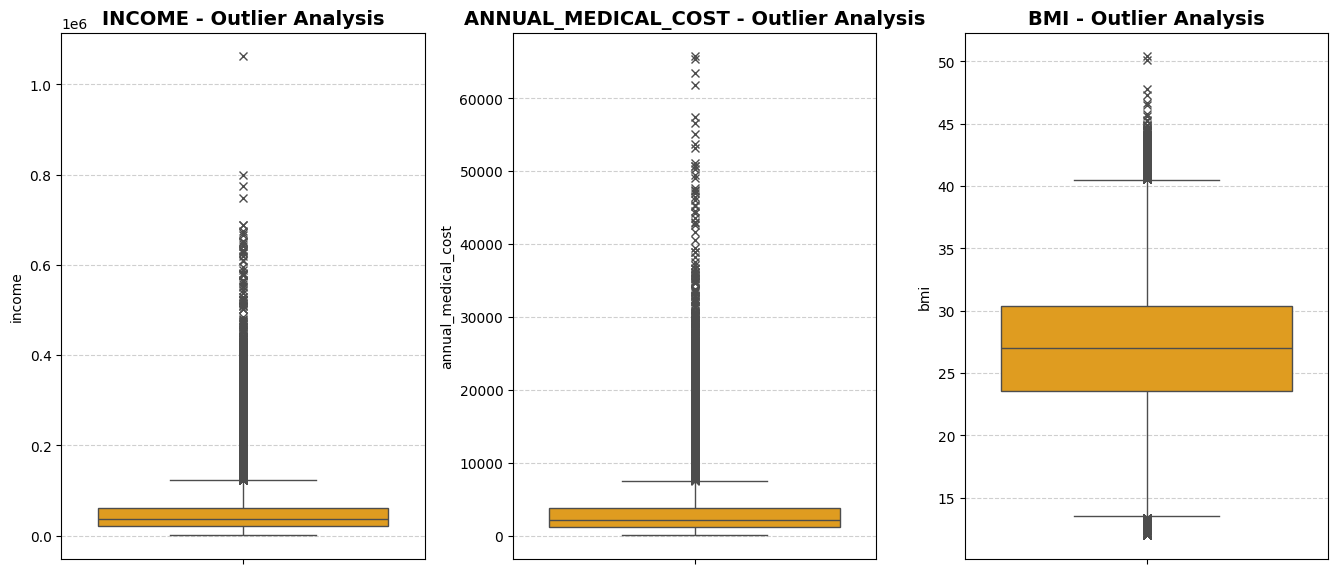

In [68]:
check_cols = ['income', 'annual_medical_cost', 'bmi']

plt.figure(figsize=(18, 6))

for i, col in enumerate(check_cols, 1):
    plt.subplot(1, 4, i)
    # Boxplot: Ortadaki kutu normal insanları, üstteki noktalar outlier'ları gösterir
    sns.boxplot(y=df[col], color='orange', flierprops={"marker": "x", "markerfacecolor": "red"})
    plt.title(f'{col.upper()} - Outlier Analysis', fontsize=14, fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()